# N01: metadata baseline

Can a visitor find a painting by describing what is **in** it ("a stormy sea with big waves")? The dataset only has
genre, style and artist (and the artist is unknown for 66% of the dev paintings), so the baseline searches that.

The ladder, one notebook per step, each compared with the previous ones on the same queries:

| Rung | Searches | Notebook |
|---|---|---|
| R0 random | nothing (the floor) | N01 |
| R1 metadata | genre + style + artist, MiniLM | N01 |
| R2 description | a VLM description of the image, MiniLM | N02 |
| R3 description + metadata | both, MiniLM | N02 |
| R4 SigLIP | the image itself, SigLIP | N03 |
| R5 hybrid | R3 + R4 | N04 |

How we measure (ADR 0007): 40 visual queries written before any result existed, the top 5 of each rung graded blind
(0 no, 1 partial, 2 clear) by an LLM judge validated against human grades (N04). Main metric **nDCG@5** (are the 5 paintings the kiosk shows good, best first?),
plus **Success@5** (is at least one a clear match?). Everything here is on **dev** (Museum A validation, 480
paintings); Museum B is scored once, in N05.

In [1]:

from deep_learning_project_waerniers_lamy.nlp import utils as u

c:\Users\Vincent\GitHub\Vincent-20-100\deep-learning-project-waerniers-lamy\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Corpus and queries

In [2]:
paintings = u.load_corpus("dev")
queries = u.QUERIES["text"].tolist()

print(len(paintings), "paintings |", (paintings["artist"] == "Unknown Artist").mean().round(2), "with unknown artist")
print(u.QUERIES["category"].value_counts().to_dict())
print("searchable text of the baseline, e.g.:", u.metadata_text(paintings.iloc[0]))
u.QUERIES.head()

480 paintings | 0.66 with unknown artist
{'object': 12, 'scene': 10, 'mood_colour': 9, 'compound': 9}
searchable text of the baseline, e.g.: cityscape painting, Impressionism style by gustave caillebotte


,query_id,category,text
0,q01,object,a vase of flowers on a table
1,q02,object,a bowl of fruit
2,q03,object,an old man with a white beard
3,q04,object,a portrait of a child
4,q05,object,a woman wearing a hat


## 2. Rank the paintings

Each rung gives a similarity between every query and every painting; the 5 highest are what the kiosk would show.

In [3]:
scores = {
    "R0 random": u.rung_random(paintings, queries),
    "R1 metadata": u.rung_metadata(paintings, queries),
}
# What the baseline shows for one query: it can only match words of the metadata.
top = u.top_k_ids(scores["R1 metadata"], paintings)[12]
print(queries[12])
paintings.set_index("id").loc[top, ["genre", "style", "artist"]]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3479.80it/s]


a stormy sea with big waves


,genre,style,artist
id,,,
s42_r0321,landscape,Realism,aleksey-savrasov
s54_r0123,landscape,Realism,aleksey-savrasov
s51_r0317,cityscape,Romanticism,jan-matejko
s42_r0120,portrait,Realism,felix-vallotton
s54_r0199,landscape,Art_Nouveau,felix-vallotton


## 3. Grade the new top-5 paintings

In [4]:
u.judge_with_llm("dev", scores, paintings)

397 new (query, painting) pairs to grade with google/gemini-3.8-flash
100/397
200/397
300/397
397 judgments in C:\Users\Vincent\GitHub\Vincent-20-100\deep-learning-project-waerniers-lamy\results\nlp\qrels_dev.json, 0 failed


{'q01': {'s51_r0672': 0,
  's58_r0692': 0,
  's49_r0203': 0,
  's51_r1050': 0,
  's58_r0276': 0,
  's42_r0523': 0,
  's51_r0941': 0,
  's51_r0277': 0,
  's51_r0947': 0,
  's54_r0082': 0},
 'q02': {'s49_r0642': 0,
  's42_r0640': 0,
  's58_r0604': 0,
  's49_r0303': 0,
  's49_r0317': 0,
  's49_r0261': 0,
  's49_r0533': 0,
  's51_r0444': 0,
  's58_r0296': 0,
  's49_r0183': 0},
 'q03': {'s54_r0333': 0,
  's54_r0460': 0,
  's54_r0726': 0,
  's54_r0496': 0,
  's49_r0454': 2,
  's54_r0346': 0,
  's54_r0278': 0,
  's54_r0550': 0,
  's54_r0375': 0,
  's49_r1014': 1},
 'q04': {'s54_r0586': 0,
  's58_r0498': 0,
  's58_r0577': 2,
  's42_r0079': 2,
  's42_r0341': 0,
  's42_r0473': 0,
  's51_r0249': 0,
  's54_r0857': 0,
  's58_r0461': 0,
  's51_r0124': 0},
 'q05': {'s58_r0692': 1,
  's42_r0323': 1,
  's58_r0498': 0,
  's42_r0679': 0,
  's54_r0235': 0,
  's51_r1076': 0,
  's54_r0714': 0,
  's58_r0380': 0,
  's42_r0731': 1,
  's58_r0512': 1},
 'q06': {'s58_r0079': 0,
  's54_r0404': 0,
  's42_r0528': 0,

### Judging

Every painting in the new top 5 of a rung is graded by an LLM judge (`u.JUDGE_MODEL`, another model family than the
description generator). It sees **only the query and the image**, answers two yes/no questions (is the main subject
there? does it match the whole query?) and the grade follows by rule: 0, 1 or 2. Grades are saved in
`results/nlp/qrels_dev.json`; already graded pairs are never sent again. The judge is validated against 150 of your own
grades in N04 before any result is frozen.

## 4. Results

A query with nothing relevant judged has no defined nDCG and is dropped (the count is shown). `judged@5` should be 1.0:
every painting shown was judged.

queries kept: 23 of 40


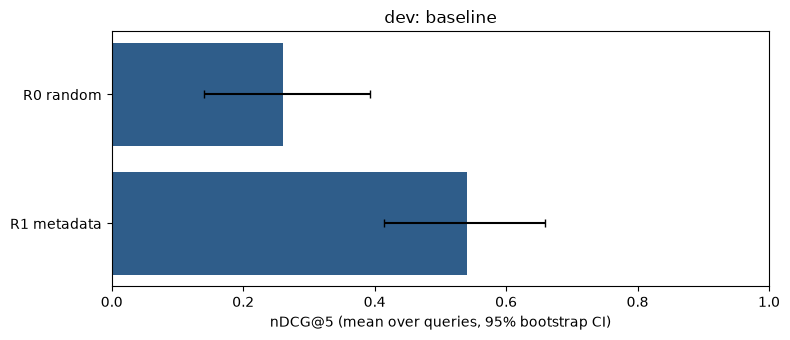

,rung,queries,nDCG@5,nDCG low,nDCG high,Success@5,Success low,Success high,judged@5
0,R0 random,23,0.26,0.141,0.393,0.217,0.043,0.391,1.0
1,R1 metadata,23,0.54,0.415,0.659,0.435,0.217,0.652,1.0


In [5]:
per_query = u.per_query_scores("dev", scores, paintings)
table = u.summary_table(per_query)
print("queries kept:", per_query["query_id"].nunique(), "of", len(queries))
u.plot_ladder(table, "dev: baseline")
table

What to look for: R1 should beat R0 on queries whose words appear in the metadata (e.g. "a portrait of a child" ->
genre portrait) and be close to random on the rest (colours, weather, objects).

In [6]:
per_query.groupby(["rung", "category"])["ndcg@5"].mean().unstack().round(3)

category,compound,mood_colour,object,scene
rung,,,,
R0 random,0.082,0.383,0.242,0.228
R1 metadata,0.785,0.533,0.422,0.495
